# Задача 2. Тележка на пружине c вязким трением

### Условие

масса m = 1 кг\
начальное смещение X0 = 0.1 м, начальная скорость V0 = 0 м/с\
жёсткости k (при c = 1) = 1, 4, 9, 16, 25 Н/м\
трение с (при k = 4) = 0.5, 1, 2, 4, 8 кг/с\
временной интервал для графиков t[0: 10] c

### Решение ДУ

Подключение библиотек

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

Символьные переменные

In [8]:
t, m, k, c = sp.symbols('t m k с', positive=True)
x = sp.Function('x')

ДУ

In [10]:
ode_x = sp.Eq(m*sp.diff(x(t), t, 2) + c*sp.diff(x(t), t) + k*x(t), 0)
sp.pprint(ode_x)

             2                       
            d            d           
k⋅x(t) + m⋅───(x(t)) + с⋅──(x(t)) = 0
             2           dt          
           dt                        


Параметры

In [12]:
m_val = 1
k_values = [1, 4, 9, 16, 25]
c_values = [sp.Rational(1, 2), 1, 2, 4, 8]
x0 = 0.1
v0 = 0
n_points = 1000
general_solutions = {}
part_solutions = {}
speed_solutions = {}

In [13]:
for k_val in k_values:
    ode = sp.Eq(m_val * sp.diff(x(t), t, 2) + c_values[1]*sp.diff(x(t), t)+ k_val * x(t), 0)

    # Общее решение
    sol_general = sp.dsolve(ode)
    general_solutions[k_val] = sol_general

    # Частное решение
    sol_part = sp.dsolve(ode, ics={x(0): x0, sp.diff(x(t), t).subs(t, 0): v0})
    part_solutions[k_val] = sol_part

    # Скорость
    v_expr = sp.simplify(sp.diff(sol_part.rhs, t))
    speed_solutions[k_val] = v_expr
print("----Одно из общих решений----")
print(f"k = {9}:")
sp.pprint(general_solutions[9])
print()
    

print("----Одно из частных решений----")
print(f"k = {9}:")
sp.pprint(part_solutions[9])
print()

----Одно из общих решений----
k = 9:
                                        -t 
                                        ───
       ⎛      ⎛√35⋅t⎞         ⎛√35⋅t⎞⎞   2 
x(t) = ⎜C₁⋅sin⎜─────⎟ + C₂⋅cos⎜─────⎟⎟⋅ℯ   
       ⎝      ⎝  2  ⎠         ⎝  2  ⎠⎠     

----Одно из частных решений----
k = 9:
                                                         -t 
                                                         ───
       ⎛                      ⎛√35⋅t⎞          ⎛√35⋅t⎞⎞   2 
x(t) = ⎜0.0169030850945703⋅sin⎜─────⎟ + 0.1⋅cos⎜─────⎟⎟⋅ℯ   
       ⎝                      ⎝  2  ⎠          ⎝  2  ⎠⎠     



### Построение графиков

In [15]:
t_vals = np.linspace(0, 10, n_points)

x_funcs = {}
v_funcs = {}

#### с = 1
#### k - разные

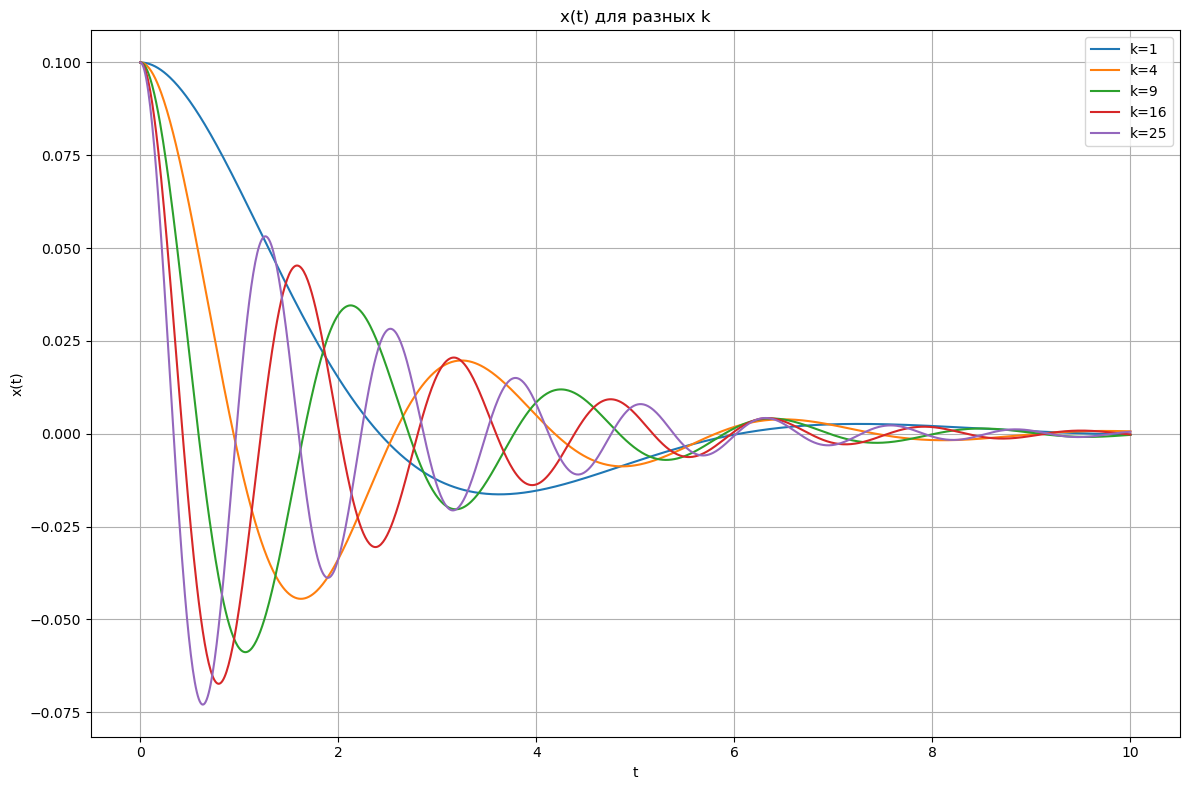

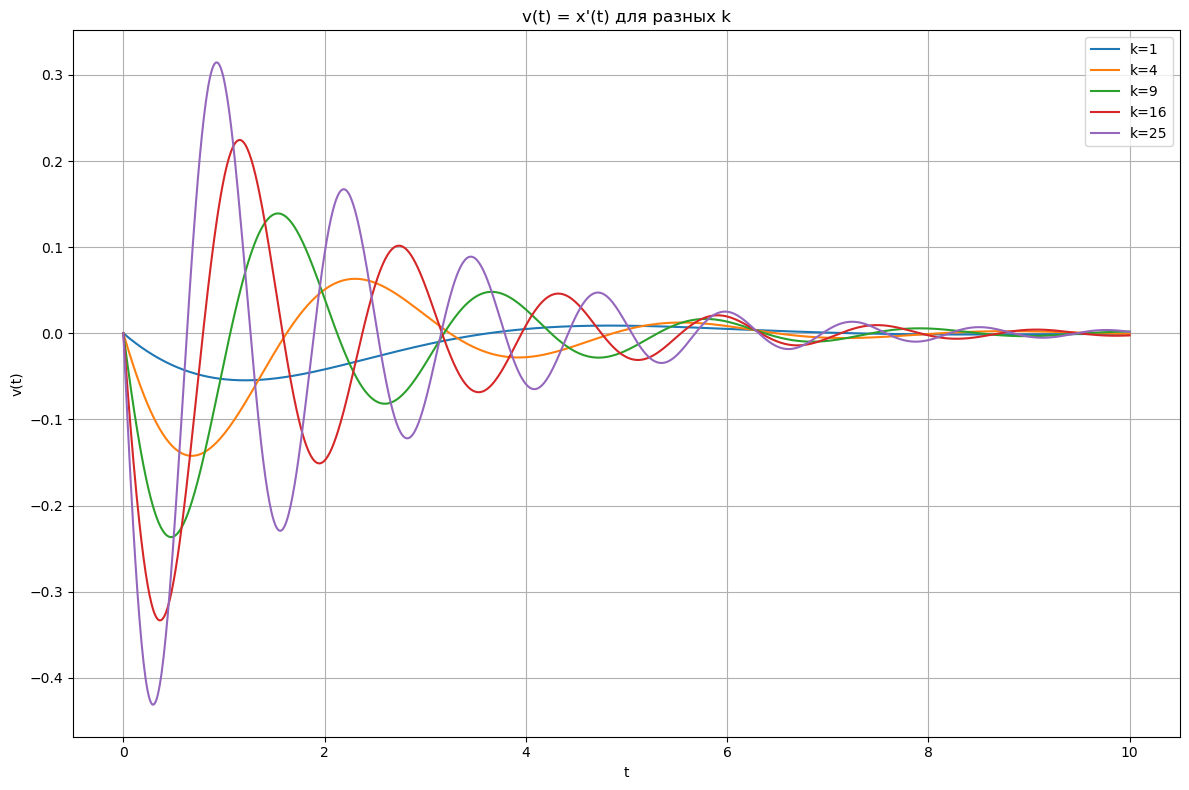

In [17]:
for k_val in k_values:
    x_expr = sp.simplify(part_solutions[k_val].rhs)
    v_expr = speed_solutions[k_val]

    x_funcs[k_val] = sp.lambdify(t, x_expr, 'numpy')
    v_funcs[k_val] = sp.lambdify(t, v_expr, 'numpy')
    
# ГРАФИК x(t)

plt.figure(figsize=(12, 8))
for k_val in k_values:
    plt.plot(t_vals, x_funcs[k_val](t_vals), label=f'k={k_val}')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('x(t) для разных k')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ГРАФИК v(t)

plt.figure(figsize=(12, 8))
for k_val in k_values:
    plt.plot(t_vals, v_funcs[k_val](t_vals), label=f'k={k_val}')
plt.xlabel('t')
plt.ylabel('v(t)')
plt.title("v(t) = x'(t) для разных k")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#### k = 4
#### c - разные

In [19]:
for c_val in c_values:
    ode = sp.Eq(m_val * sp.diff(x(t), t, 2) + c_val*sp.diff(x(t), t)+ k_values[1] * x(t), 0)

    # Общее решение
    sol_general = sp.dsolve(ode)
    general_solutions[c_val] = sol_general

    # Частное решение
    sol_part = sp.dsolve(ode, ics={x(0): x0, sp.diff(x(t), t).subs(t, 0): v0})
    part_solutions[c_val] = sol_part

    # Скорость
    v_expr = sp.simplify(sp.diff(sol_part.rhs, t))
    speed_solutions[c_val] = v_expr

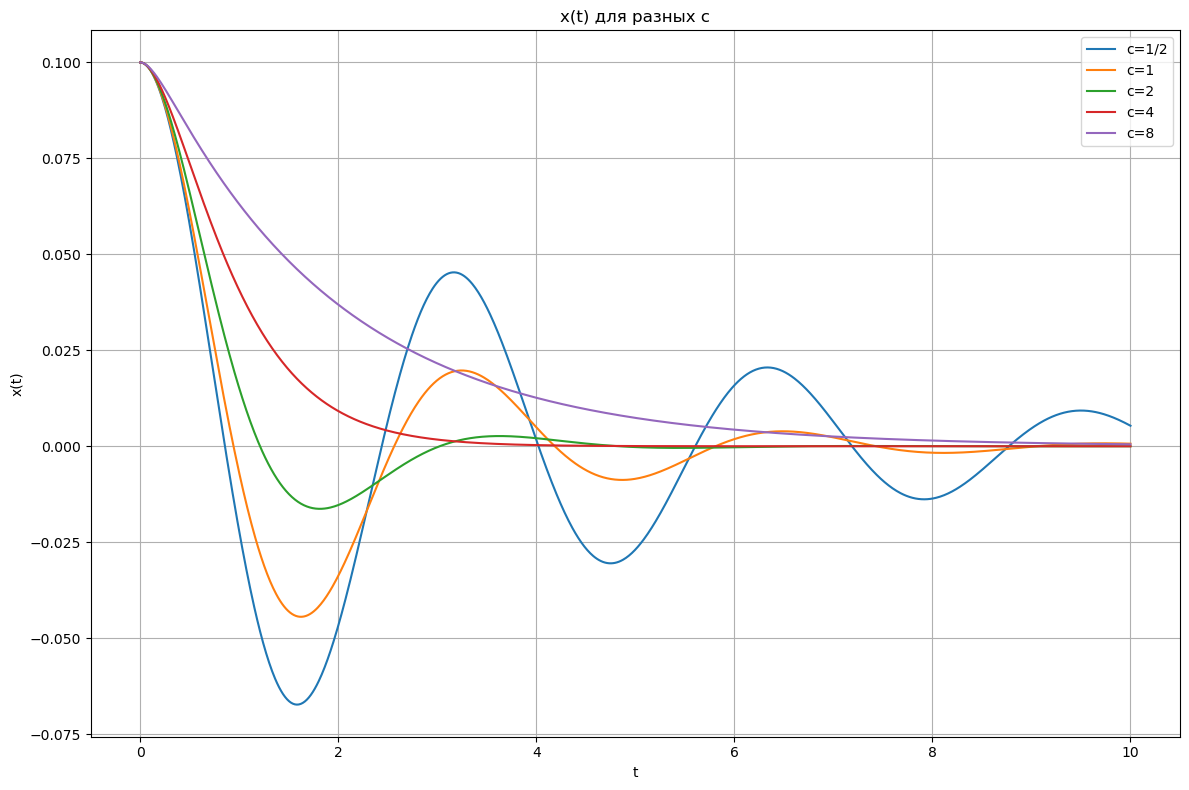

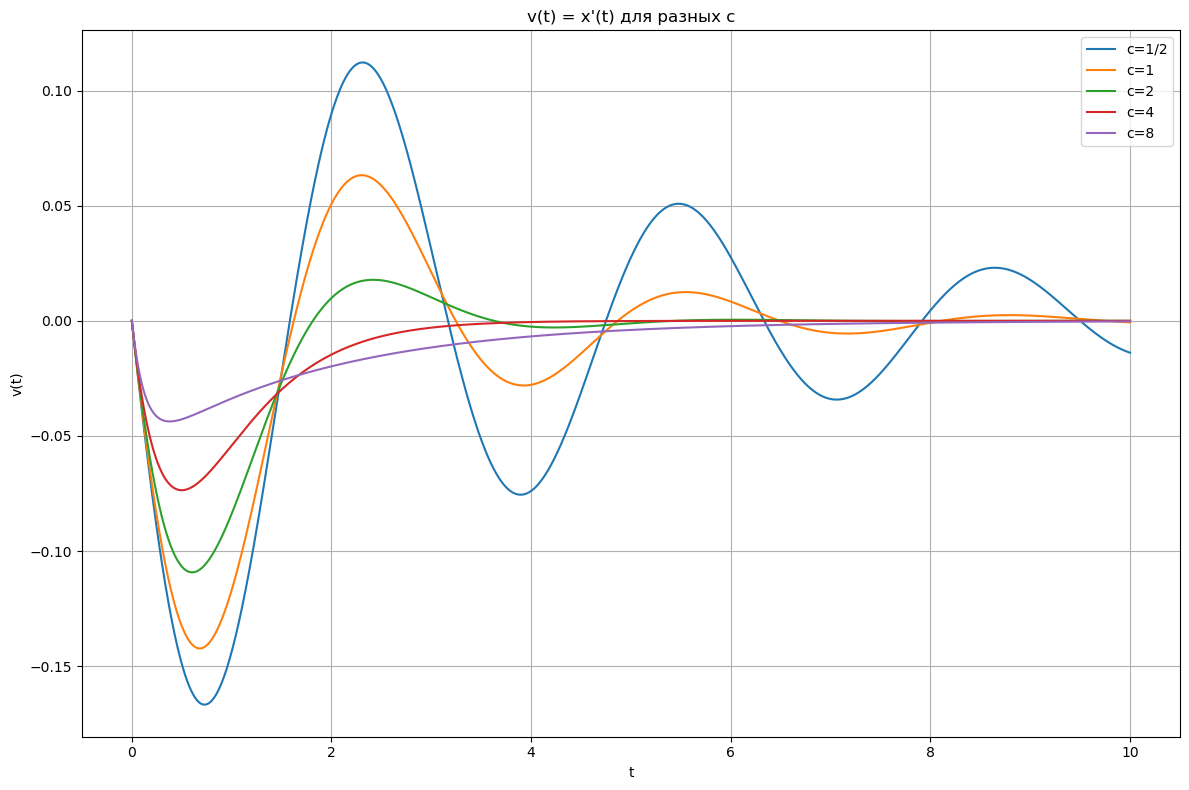

In [20]:
for c_val in c_values:
    x_expr = sp.simplify(part_solutions[c_val].rhs)
    v_expr = speed_solutions[c_val]

    x_funcs[c_val] = sp.lambdify(t, x_expr, 'numpy')
    v_funcs[c_val] = sp.lambdify(t, v_expr, 'numpy')
    
# ГРАФИК x(t)

plt.figure(figsize=(12, 8))
for c_val in c_values:
    plt.plot(t_vals, x_funcs[c_val](t_vals), label=f'с={c_val}')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('x(t) для разных c')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ГРАФИК v(t)

plt.figure(figsize=(12, 8))
for c_val in c_values:
    plt.plot(t_vals, v_funcs[c_val](t_vals), label=f'с={c_val}')
plt.xlabel('t')
plt.ylabel('v(t)')
plt.title("v(t) = x'(t) для разных c")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#### Фазовый портрет

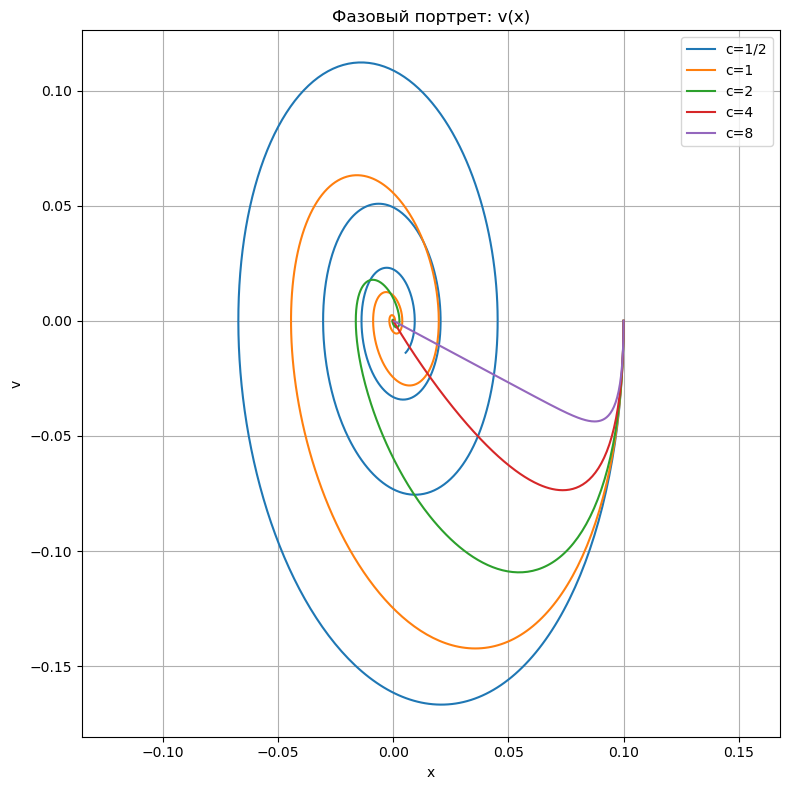

In [22]:
plt.figure(figsize=(8, 8))
for c_val in c_values:
    x_num = x_funcs[c_val](t_vals)
    v_num = v_funcs[c_val](t_vals)
    plt.plot(x_num, v_num, label=f'с={c_val}')
plt.xlabel('x')
plt.ylabel('v')
plt.title('Фазовый портрет: v(x)')
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.tight_layout()
plt.show()

#### c_crit = 2 * sqrt(k*m)
##### k = 4

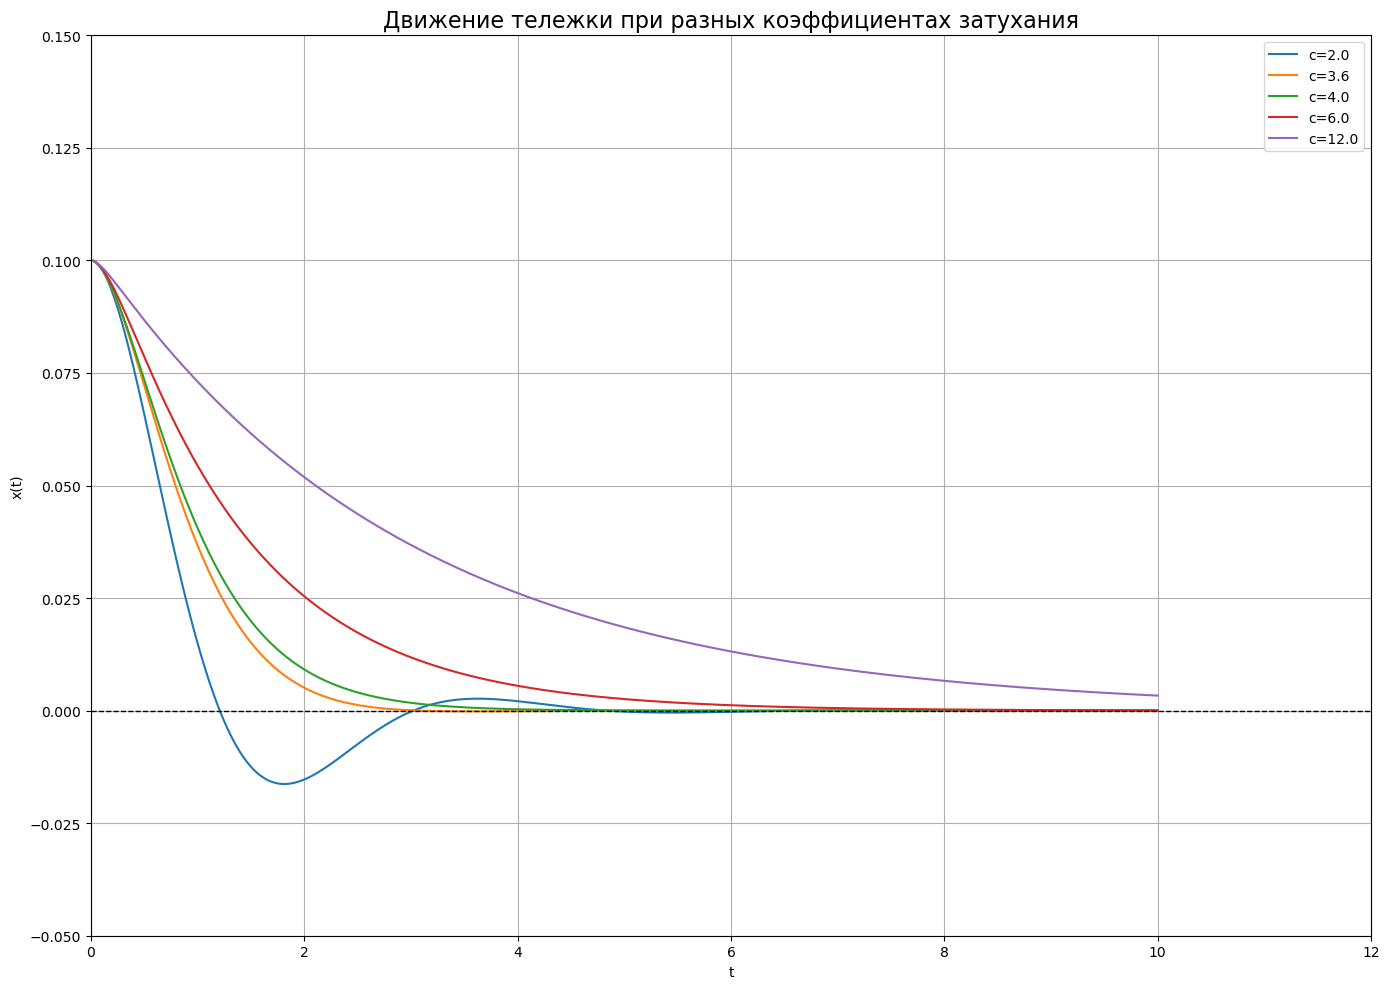

In [39]:
c_crit = 4
c_values_plus = [
    0.5 * c_crit,
    0.9 * c_crit,
    c_crit,
    1.5 * c_crit,
    3.0 * c_crit
]
part_solutions = {}
x_funcs = {}

for c_val in c_values_plus:
    ode = sp.Eq(m_val * sp.diff(x(t), t, 2) + c_val * sp.diff(x(t), t) + 4 * x(t),0)

    sol_part = sp.dsolve(ode,ics={x(0): x0,sp.diff(x(t), t).subs(t, 0): v0})

    x_expr = sp.simplify(sol_part.rhs)
    part_solutions[c_val] = x_expr
    x_funcs[c_val] = sp.lambdify(t, x_expr, 'numpy')

plt.figure(figsize=(14, 10))

for c_val in c_values_plus:
    plt.plot(t_vals, x_funcs[c_val](t_vals), label=f'c={c_val:.1f}')

plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title("Движение тележки при разных коэффициентах затухания", fontsize=16)
plt.xlabel('t')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.xlim(0, 12)
plt.ylim(-0.05, 0.15)
plt.tight_layout()
plt.show()